# 04_01 The Family Tree of Distributions: How They Are Related

**Learning objectives**
- See that the dozens of named distributions are **not separate inventions**: they are built from each other by **six mechanisms** (sum, transformation, limit, special case, mixture, conditioning).
- Know the most important relationships by heart, with their one-line proofs (each followed by an "In plain words" explanation).
- **Verify every relationship by simulation** (a table of about 30 checks) and spot the special cases directly in `scipy`.
- Use the relationships to **solve a problem in several ways and get the same answer** (a call center seen as Poisson, Exponential, Gamma and Binomial at once).

**Prerequisites:** Modules 01 to 03, in particular [01_03 Poisson](../../module_01_discrete/notebooks/01_03_poisson.ipynb), [02_03 Exponential and Gamma](../../module_02_continuous/notebooks/02_03_exponential_gamma_erlang.ipynb) and [02_08 t, chi-square and F](../../module_02_continuous/notebooks/02_08_t_chisquare_f.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap: the cast

One line per family, so that the relationships below make sense.

| Family | What it describes |
|---|---|
| Bernoulli, Binomial | one yes/no trial; successes in $n$ independent trials |
| Geometric, Negative Binomial | trials until the first / $r$-th success |
| Poisson | events in a window at a constant rate |
| Hypergeometric | successes when sampling without replacement |
| Uniform | every value in an interval equally likely |
| Normal, Lognormal | sums of many effects; products of many factors |
| Exponential, Gamma, Weibull | waiting times, lifetimes |
| Beta, Dirichlet | unknown probabilities, probability vectors |
| Pareto, Cauchy, Laplace, Logistic, Gumbel | heavy tails, absolute errors, sigmoid, maxima |
| $\chi^2$, t, F | sampling distributions built from Normals |

Also needed: the **MGF/PGF** of a sum of independent variables is the product of the MGFs/PGFs; the **CDF method** for a function $Y=g(X)$; **conditional probability**.

## 3. Intuition and story

Imagine all distributions as one **family tree**. A newcomer never starts from scratch: a Binomial is *a sum of Bernoullis*, a Gamma is *a sum of Exponentials*, a chi-square is *a sum of squared Normals*, a Student t is *a Normal divided by a chi-square*. Knowing **how a distribution is built** tells you three things at once: where it comes from (the story), what its mean and variance must be (sums of means and variances), and how to simulate it (run the recipe).

There are only **six ways** to build one distribution from another:

| # | Mechanism | One-line idea | Example |
|---|---|---|---|
| 1 | **Sum** of independent variables | add up independent copies | Bernoulli $\to$ Binomial; Exponential $\to$ Gamma |
| 2 | **Transformation** $Y=g(X)$ | apply a function | $e^{\text{Normal}}=$ Lognormal; $-\ln U/\lambda=$ Exponential |
| 3 | **Limit** | let a parameter go to infinity | Binomial $\to$ Poisson $\to$ Normal |
| 4 | **Special case** | fix a parameter | Exponential = Gamma($k=1$); Cauchy = $t_1$ |
| 5 | **Mixture** | let a parameter itself be random | Gamma-Poisson = Negative Binomial |
| 6 | **Conditioning** | look at a subset of the world | Poisson given the sum = Binomial |

The rest of the notebook walks through each mechanism, proves one or two key links, and then **checks all of them numerically**.

## 4. Formal definition: the six mechanisms

1. **Sum:** $S=X_1+\dots+X_n$ with independent $X_i$. Tool: $M_S(t)=\prod M_{X_i}(t)$.
2. **Transformation:** $Y=g(X)$. Tool: CDF method, or $f_Y(y)=f_X(g^{-1}(y))\,|dg^{-1}/dy|$.
3. **Limit:** $F_n\to F$ as $n\to\infty$ (convergence in distribution). Tool: MGF/PGF limits, the Central Limit Theorem.
4. **Special case:** $\text{Family}(\theta_0)=\text{SmallerFamily}$ for a particular parameter value.
5. **Mixture:** $X\mid\Theta\sim F_\Theta$ with $\Theta\sim G$; the marginal law is $\int F_\theta\,dG(\theta)$.
6. **Conditioning:** the law of $X$ given an event or given another variable's value.

## 5. Derivations: one key link for every mechanism

### 5.1 Sum: Bernoulli to Binomial, Exponential to Gamma (via MGFs)
A Bernoulli($p$) has PGF $1-p+ps$; the sum of $n$ independent copies has PGF $(1-p+ps)^n$, which is the Binomial($n,p$) PGF. An Exponential($\lambda$) has MGF $\frac\lambda{\lambda-t}$; the sum of $k$ copies has MGF $\big(\frac\lambda{\lambda-t}\big)^k$, the Gamma($k$, scale $1/\lambda$) MGF.
**In plain words.** Because "adding independent variables multiplies their generating functions", repeated addition keeps you inside a family and just raises the parameter: $n$ trials, $k$ waits.

### 5.2 Transformation: uniform to anything (inverse CDF), Normal to Lognormal
If $U\sim\text{Uniform}(0,1)$ then $F^{-1}(U)$ has CDF $F$, because $P(F^{-1}(U)\le x)=P(U\le F(x))=F(x)$. With $F(x)=1-e^{-\lambda x}$ this gives $-\ln(1-U)/\lambda$ (and $-\ln U/\lambda$, since $1-U$ is also uniform): the Exponential. For $Y=e^X$ with $X\sim N(\mu,\sigma^2)$: $P(e^X\le y)=P(X\le\ln y)=\Phi\big(\frac{\ln y-\mu}\sigma\big)$, the Lognormal CDF.
**In plain words.** The Uniform is the raw material of simulation: push it through the inverse CDF of any distribution and you get that distribution.

### 5.3 Limit: Binomial to Poisson, then to Normal
With $p=\lambda/n$: $\binom nk p^k(1-p)^{n-k}\to e^{-\lambda}\lambda^k/k!$ (derived in 01_03). A Poisson($\lambda$) is a sum of $\lambda$ independent Poisson(1) variables for integer $\lambda$, so by the CLT it is close to Normal($\lambda,\lambda$) when $\lambda$ is large.
**In plain words.** Many rare chances look like random arrivals (Poisson); many random arrivals look like a bell (Normal): a chain of approximations (quantified in 04_02).

### 5.4 Special case: read it off the formula
Gamma density $\propto x^{k-1}e^{-x/\theta}$: with $k=1$ it is $e^{-x/\theta}$ (Exponential); with $k=\nu/2$, $\theta=2$ it is $x^{\nu/2-1}e^{-x/2}$ (chi-square). Student t density $\propto(1+x^2/\nu)^{-(\nu+1)/2}$: with $\nu=1$ it is $\frac1{1+x^2}$ (Cauchy). Beta($1,1$) density is constant (Uniform). Negative Binomial with $r=1$ is the Geometric.
**In plain words.** A special case is the same formula with a particular parameter plugged in, so it needs no proof, only recognition.

### 5.5 Mixture: Gamma-Poisson gives the Negative Binomial
Let $\Lambda\sim\text{Gamma}(r,\text{scale }\theta)$ and $N\mid\Lambda\sim\text{Poisson}(\Lambda)$. Then
$$P(N=k)=\int_0^\infty\frac{e^{-\lambda}\lambda^k}{k!}\frac{\lambda^{r-1}e^{-\lambda/\theta}}{\Gamma(r)\theta^r}d\lambda=\frac{\Gamma(r+k)}{k!\,\Gamma(r)}\Big(\frac1{1+\theta}\Big)^r\Big(\frac\theta{1+\theta}\Big)^k,$$
which is the Negative Binomial with $p=\frac1{1+\theta}$. Its variance exceeds its mean, because the rate itself varies (law of total variance: $\mathrm{Var}(N)=E[\Lambda]+\mathrm{Var}(\Lambda)$).
**In plain words.** If every customer has their own purchase rate, the *population* counts are more spread out than a single Poisson: that is overdispersion, and the Negative Binomial is its model.

### 5.6 Conditioning: Poisson given the total is Binomial
Let $X\sim\text{Poi}(\lambda_1)$, $Y\sim\text{Poi}(\lambda_2)$ independent. Then
$$P(X=k\mid X+Y=n)=\frac{P(X=k)P(Y=n-k)}{P(X+Y=n)}=\binom nk\Big(\frac{\lambda_1}{\lambda_1+\lambda_2}\Big)^k\Big(\frac{\lambda_2}{\lambda_1+\lambda_2}\Big)^{n-k}.$$
**In plain words.** If you know 20 calls arrived in total, each one is "spam" independently with the *fixed* probability $\lambda_1/(\lambda_1+\lambda_2)$: the random total has been replaced by a known number of trials, and Poisson turns into Binomial.

## 6. Properties and relationships: the master registry

The table lists the relationships verified below (the lesson that proves each one is in the last column).

| # | Mechanism | Statement | Lesson |
|---|---|---|---|
| 1-3 | Sum | Bernoulli sum = Binomial; Geometric sum = Neg. Binomial; Exponential sum = Gamma | 01_01, 01_02, 02_03 |
| 4-6 | Sum | Poisson + Poisson = Poisson; Normal + Normal = Normal; Gamma + Gamma (same scale) = Gamma | 01_03, 02_01, 02_03 |
| 7-8 | Sum | sum of squared Normals = $\chi^2$; Binomial + Binomial (same $p$) = Binomial | 02_08, 01_01 |
| 9-12 | Transform | $e^{\text{Normal}}$ = Lognormal; $-\ln U/\lambda$ = Exponential; $\lambda E^{1/k}$ = Weibull; $x_me^{E/\alpha}$ = Pareto | 02_02, 02_03, 02_05, 02_06 |
| 13-16 | Transform | $Z/\sqrt{\chi^2_\nu/\nu}$ = t; ratio of $\chi^2$ = F; $Z_1/Z_2$ = Cauchy; $X/(X+Y)$ of Gammas = Beta | 02_08, 02_06, 02_04 |
| 17-19 | Transform | Exp $-$ Exp = Laplace; Gumbel $-$ Gumbel = Logistic; $t_\nu^2$ = $F_{1,\nu}$ | 02_07, 02_08 |
| 20-25 | Limit | Binomial $\to$ Poisson; Binomial, Poisson, Gamma, t $\to$ Normal; Hypergeometric $\to$ Binomial; maxima $\to$ Gumbel | 01_01, 01_03, 02_08, 02_07 |
| 26-28 | Mixture | Gamma-Poisson = Neg. Binomial; Beta-Binomial; Normal scale mixture = t | 01_02, 02_04, 02_08 |
| 29-31 | Conditioning | Poisson given sum = Binomial; order statistics of Uniforms = Beta; memoryless Exponential | 01_03, 02_04, 02_03 |
| - | Special cases | Exponential = Gamma(1); $\chi^2$ = Gamma($\nu/2$, 2); Cauchy = $t_1$; Beta(1,1) = Uniform; Weibull(1) = Exponential; Geometric = NegBin(1); Bernoulli = Binomial(1) | checked in section 10 |

## 7. 2D visuals

### 7.1 The family tree
Each arrow is one relationship, colored by its mechanism. Hubs (the Normal, the Exponential, the Gamma) show which distributions are the building blocks.

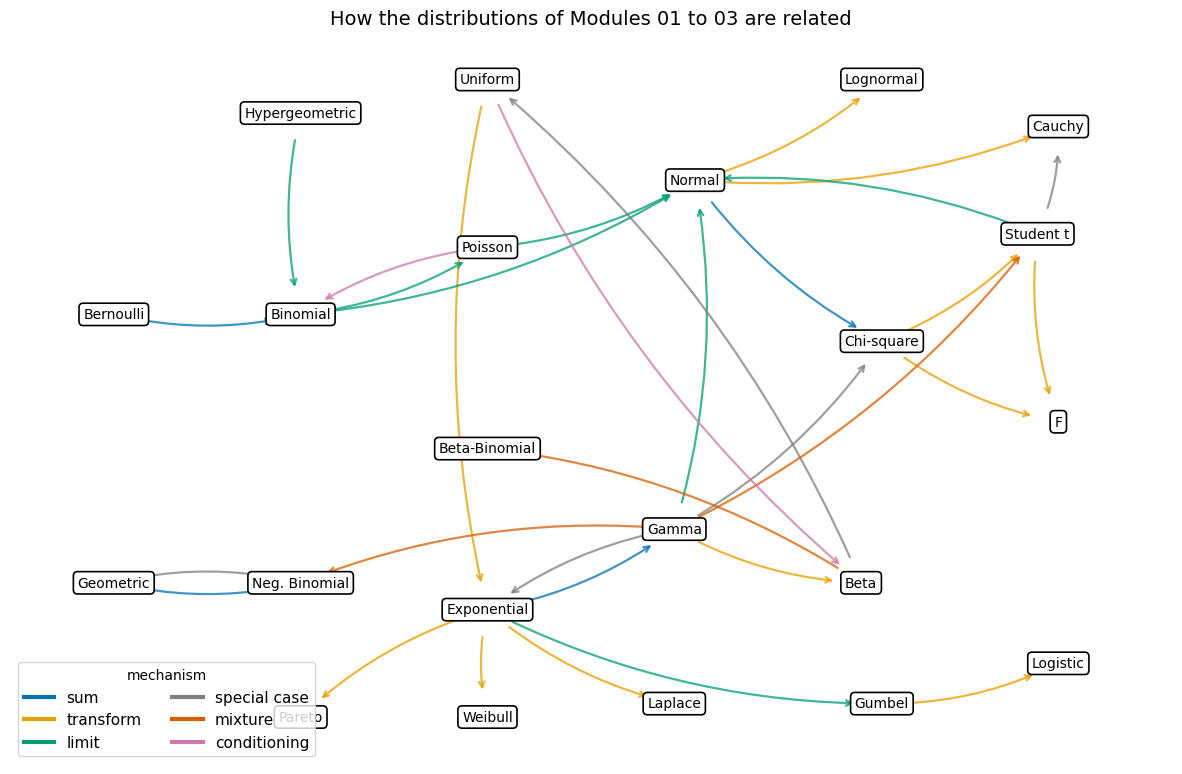

22 distributions, 32 relationships


In [2]:
positions = {
    "Bernoulli": (0.06, 0.62), "Binomial": (0.24, 0.62), "Hypergeometric": (0.24, 0.92), "Poisson": (0.42, 0.72), "Geometric": (0.06, 0.22), "Neg. Binomial": (0.24, 0.22), "Beta-Binomial": (0.42, 0.42),
    "Uniform": (0.42, 0.97), "Exponential": (0.42, 0.18), "Gamma": (0.60, 0.30), "Weibull": (0.42, 0.02), "Pareto": (0.24, 0.02), "Laplace": (0.60, 0.04),
    "Normal": (0.62, 0.82), "Lognormal": (0.80, 0.97), "Chi-square": (0.80, 0.58), "Student t": (0.95, 0.74), "F": (0.97, 0.46), "Cauchy": (0.97, 0.90), "Beta": (0.78, 0.22), "Gumbel": (0.80, 0.04), "Logistic": (0.97, 0.10),
}
edges = [  # (source, target, mechanism)
    ("Bernoulli", "Binomial", "sum"), ("Geometric", "Neg. Binomial", "sum"), ("Exponential", "Gamma", "sum"), ("Normal", "Chi-square", "sum"),
    ("Uniform", "Exponential", "transform"), ("Normal", "Lognormal", "transform"), ("Exponential", "Weibull", "transform"), ("Exponential", "Pareto", "transform"),
    ("Chi-square", "Student t", "transform"), ("Chi-square", "F", "transform"), ("Normal", "Cauchy", "transform"), ("Gamma", "Beta", "transform"),
    ("Exponential", "Laplace", "transform"), ("Gumbel", "Logistic", "transform"), ("Student t", "F", "transform"),
    ("Binomial", "Poisson", "limit"), ("Binomial", "Normal", "limit"), ("Poisson", "Normal", "limit"), ("Gamma", "Normal", "limit"), ("Student t", "Normal", "limit"),
    ("Hypergeometric", "Binomial", "limit"), ("Exponential", "Gumbel", "limit"),
    ("Gamma", "Chi-square", "special case"), ("Student t", "Cauchy", "special case"), ("Neg. Binomial", "Geometric", "special case"), ("Beta", "Uniform", "special case"), ("Gamma", "Exponential", "special case"),
    ("Gamma", "Neg. Binomial", "mixture"), ("Beta", "Beta-Binomial", "mixture"), ("Gamma", "Student t", "mixture"),
    ("Poisson", "Binomial", "conditioning"), ("Uniform", "Beta", "conditioning"),
]
mechanism_color = {"sum": COLORS[0], "transform": COLORS[1], "limit": COLORS[2], "special case": "#7f7f7f", "mixture": COLORS[3], "conditioning": COLORS[5]}
fig, ax = plt.subplots(figsize=(15, 9.5))
for source, target, mechanism in edges:
    (x1, y1), (x2, y2) = positions[source], positions[target]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=mechanism_color[mechanism], lw=1.6, alpha=0.75, shrinkA=20, shrinkB=20, connectionstyle="arc3,rad=0.12"))
for name, (x, y) in positions.items():
    ax.text(x, y, name, ha="center", va="center", fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=1.2))
for mechanism, color in mechanism_color.items():
    ax.plot([], [], color=color, lw=3, label=mechanism)
ax.legend(loc="lower left", title="mechanism", ncol=2)
ax.set_xlim(-0.04, 1.08); ax.set_ylim(-0.05, 1.04)
ax.axis("off")
ax.set_title("How the distributions of Modules 01 to 03 are related")
plt.show()
print(len(positions), "distributions,", len(edges), "relationships")

### 7.2 Which distributions are hubs?
Counting arrows in and out of each node: the Normal receives the limits, the Exponential and the Gamma generate many others.

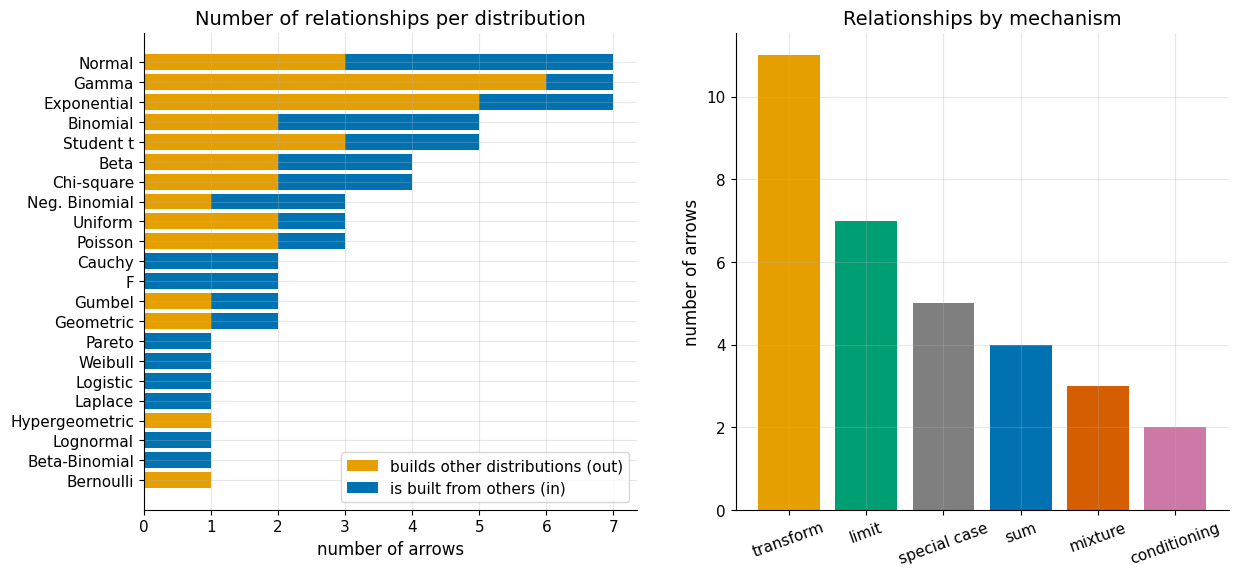

In [3]:
degree = pd.DataFrame({"out": pd.Series([s for s, t, m in edges]).value_counts(), "in": pd.Series([t for s, t, m in edges]).value_counts()}).fillna(0).astype(int)
degree["total"] = degree["out"] + degree["in"]
degree = degree.sort_values("total", ascending=True)
fig, (ax_deg, ax_mech) = plt.subplots(1, 2, figsize=(14, 6.2))
ax_deg.barh(degree.index, degree["out"], color=COLORS[1], label="builds other distributions (out)")
ax_deg.barh(degree.index, degree["in"], left=degree["out"], color=COLORS[0], label="is built from others (in)")
ax_deg.set_title("Number of relationships per distribution")
ax_deg.set_xlabel("number of arrows")
ax_deg.legend()
counts = pd.Series([m for s, t, m in edges]).value_counts()
ax_mech.bar(counts.index, counts.values, color=[mechanism_color[m] for m in counts.index])
ax_mech.set_title("Relationships by mechanism")
ax_mech.set_ylabel("number of arrows")
plt.setp(ax_mech.get_xticklabels(), rotation=20)
plt.show()

### 7.3 Seeing a sum: a Gamma from Exponentials, a Binomial from Bernoullis
Adding more and more independent pieces moves you along a family: k Exponentials give Gamma(k), n Bernoullis give Binomial(n).

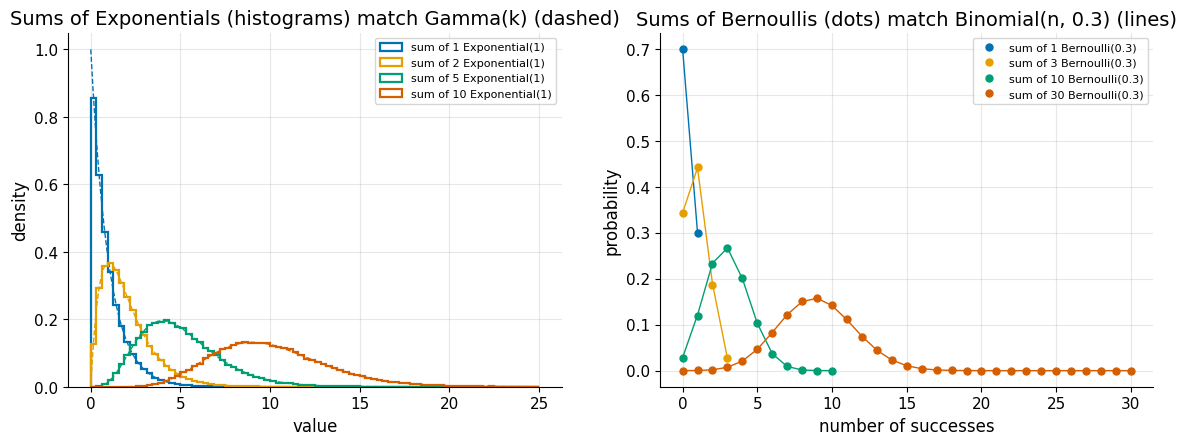

In [4]:
fig, (ax_gamma, ax_binom) = plt.subplots(1, 2, figsize=(14, 4.6))
x_axis = np.linspace(0, 25, 400)
for k, color in zip([1, 2, 5, 10], COLORS):
    sums = rng.exponential(1.0, size=(100_000, k)).sum(axis=1)
    ax_gamma.hist(sums, bins=80, range=(0, 25), density=True, histtype="step", color=color, linewidth=1.6, label=f"sum of {k} Exponential(1)")
    ax_gamma.plot(x_axis, stats.gamma(k).pdf(x_axis), "--", color=color, linewidth=1)
ax_gamma.set_title("Sums of Exponentials (histograms) match Gamma(k) (dashed)")
ax_gamma.set_xlabel("value")
ax_gamma.set_ylabel("density")
ax_gamma.legend(fontsize=8)
for n, color in zip([1, 3, 10, 30], COLORS):
    counts = (rng.random(size=(100_000, n)) < 0.3).sum(axis=1)
    ks = np.arange(0, n + 1)
    ax_binom.plot(ks, np.bincount(counts, minlength=n + 1) / len(counts), "o", color=color, markersize=5, label=f"sum of {n} Bernoulli(0.3)")
    ax_binom.plot(ks, stats.binom(n, 0.3).pmf(ks), "-", color=color, linewidth=1)
ax_binom.set_title("Sums of Bernoullis (dots) match Binomial(n, 0.3) (lines)")
ax_binom.set_xlabel("number of successes")
ax_binom.set_ylabel("probability")
ax_binom.legend(fontsize=8)
plt.show()

## 8. 3D visuals

### 8.1 Static: a Gamma becomes Normal as k grows (a limit, seen in 3D)
We standardize (subtract the mean, divide by the SD) so that every Gamma has mean 0 and SD 1, and plot its density over (z, k). The ridge flattens into the standard Normal bell as k increases.

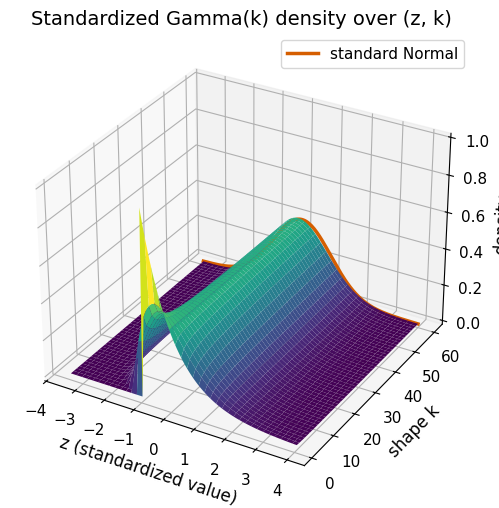

In [5]:
z_values = np.linspace(-3.5, 4, 160)
k_values = np.linspace(1, 60, 50)
Z, K = np.meshgrid(z_values, k_values)
standardized_gamma = np.sqrt(K) * stats.gamma.pdf(np.sqrt(K) * Z + K, a=K)          # density of (X - k) / sqrt(k) for X ~ Gamma(k)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Z, K, standardized_gamma, cmap="viridis", edgecolor="none")
ax.plot(z_values, np.full_like(z_values, 60), stats.norm.pdf(z_values), color=HIGHLIGHT, linewidth=2.5, label="standard Normal")
ax.set_title("Standardized Gamma(k) density over (z, k)")
ax.set_xlabel("z (standardized value)")
ax.set_ylabel("shape k")
ax.set_zlabel("density")
ax.legend()
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: the Binomial PMF turning into the Poisson PMF
For a fixed mean of 4 (p = 4/n), the surface of the Binomial PMF over (k, n) converges to the Poisson(4) pmf as n grows.

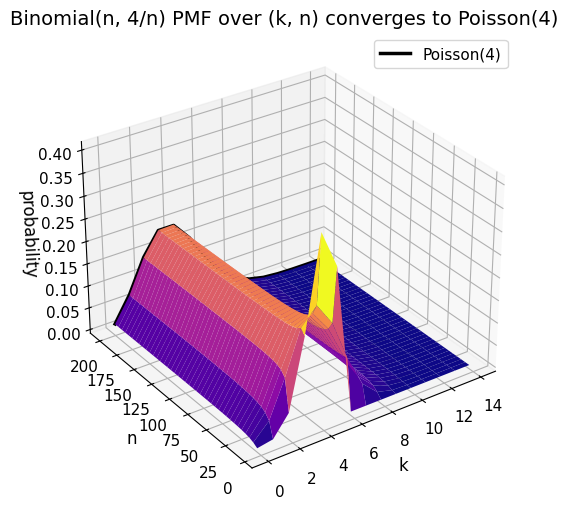

In [6]:
ks = np.arange(0, 15)
ns = np.arange(5, 201, 5)
KK, NN = np.meshgrid(ks, ns)
binomial_surface = stats.binom.pmf(KK, NN, 4 / NN)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(KK, NN, binomial_surface, cmap="plasma", edgecolor="none")
ax.plot(ks, np.full_like(ks, 200), stats.poisson(4).pmf(ks), color="black", linewidth=2.5, label="Poisson(4)")
ax.set_title("Binomial(n, 4/n) PMF over (k, n) converges to Poisson(4)")
ax.set_xlabel("k")
ax.set_ylabel("n")
ax.set_zlabel("probability")
ax.legend()
ax.view_init(elev=30, azim=-125)
plt.show()

### 8.3 Interactive Plotly version of 8.1
Drag to rotate; the surface settles onto the Normal bell.

In [7]:
fig = go.Figure(go.Surface(x=z_values, y=k_values, z=standardized_gamma, colorscale="Viridis"))
fig.update_layout(title="Standardized Gamma(k) density over (z, k)", width=750, height=550, scene=dict(xaxis_title="z", yaxis_title="shape k", zaxis_title="density"))
fig.show()

## 9. Simulation vs theory: verifying every relationship

For each relationship we run the **recipe** on the left with 200,000 draws and compare with the **target** distribution on the right. For continuous variables we use the Kolmogorov-Smirnov test (a large p-value means the simulated values are consistent with the target); for discrete variables we use the **total variation distance** between the simulated and exact PMF (near 0 is good). Relationships marked *limit* are only approximate, so we report the distance instead of a p-value.

In [8]:
n = 200_000
E = lambda scale, size: rng.exponential(scale, size)
U = lambda size: rng.uniform(size=size)
chi2_sample = lambda df, size: (rng.normal(size=(size, df)) ** 2).sum(axis=1)

continuous = [   # (mechanism, statement, simulated values, target CDF)
    ("sum", "Exponential(2) x 5 added = Gamma(5, scale 2)", E(2, (n, 5)).sum(axis=1), stats.gamma(5, scale=2).cdf),
    ("sum", "Normal(1, 2) + Normal(3, 1.5) = Normal(4, 2.5)", rng.normal(1, 2, n) + rng.normal(3, 1.5, n), stats.norm(4, 2.5).cdf),
    ("sum", "Gamma(2, 3) + Gamma(4, 3) = Gamma(6, scale 3)", rng.gamma(2, 3, n) + rng.gamma(4, 3, n), stats.gamma(6, scale=3).cdf),
    ("sum", "5 squared standard Normals added = chi-square(5)", chi2_sample(5, n), stats.chi2(5).cdf),
    ("transform", "exp(Normal(0, 0.8)) = Lognormal(0, 0.8)", np.exp(rng.normal(0, 0.8, n)), stats.lognorm(0.8).cdf),
    ("transform", "-ln(U) / 2 = Exponential(rate 2)", -np.log(U(n)) / 2, stats.expon(scale=0.5).cdf),
    ("transform", "3 E^(1/1.5) with E ~ Exp(1) = Weibull(1.5, 3)", 3 * E(1, n) ** (1 / 1.5), stats.weibull_min(1.5, scale=3).cdf),
    ("transform", "2 exp(Exp(rate 3)) = Pareto(3, x_m = 2)", 2 * np.exp(E(1 / 3, n)), stats.pareto(3, scale=2).cdf),
    ("transform", "Z / sqrt(chi2_5 / 5) = Student t(5)", rng.normal(size=n) / np.sqrt(chi2_sample(5, n) / 5), stats.t(5).cdf),
    ("transform", "(chi2_5 / 5) / (chi2_8 / 8) = F(5, 8)", (chi2_sample(5, n) / 5) / (chi2_sample(8, n) / 8), stats.f(5, 8).cdf),
    ("transform", "Z1 / Z2 = Cauchy", rng.normal(size=n) / rng.normal(size=n), stats.cauchy().cdf),
    ("transform", "X / (X + Y), X ~ Gamma(3), Y ~ Gamma(2) = Beta(3, 2)", (lambda a, b: a / (a + b))(rng.gamma(3, size=n), rng.gamma(2, size=n)), stats.beta(3, 2).cdf),
    ("transform", "Exp(1) - Exp(1) = Laplace(0, 1)", E(1, n) - E(1, n), stats.laplace().cdf),
    ("transform", "Gumbel - Gumbel = Logistic", rng.gumbel(size=n) - rng.gumbel(size=n), stats.logistic().cdf),
    ("transform", "t(7) squared = F(1, 7)", rng.standard_t(7, n) ** 2, stats.f(1, 7).cdf),
    ("mixture", "Normal(0, 1 / W), W ~ Gamma(3, rate 3) = Student t(6)", rng.normal(size=n) / np.sqrt(rng.gamma(3, 1 / 3, n)), stats.t(6).cdf),
    ("conditioning", "3rd smallest of 5 Uniforms = Beta(3, 3)", np.sort(U((n, 5)), axis=1)[:, 2], stats.beta(3, 3).cdf),
    ("conditioning", "Exp(4) minus 5, given it exceeds 5 = Exp(4) (memoryless)", (lambda w: w[w > 5] - 5)(E(4, 3 * n)), stats.expon(scale=4).cdf),
]
rows = []
for mechanism, statement, samples, cdf in continuous:
    statistic, p_value = stats.kstest(samples[:20_000], cdf)
    rows.append({"mechanism": mechanism, "relationship": statement, "KS statistic": round(statistic, 4), "p-value": round(p_value, 3), "verified": p_value > 0.001})
continuous_table = pd.DataFrame(rows)
print(continuous_table.to_string(index=False))
assert continuous_table["verified"].all()

   mechanism                                             relationship  KS statistic  p-value  verified
         sum             Exponential(2) x 5 added = Gamma(5, scale 2)        0.0051    0.677      True
         sum           Normal(1, 2) + Normal(3, 1.5) = Normal(4, 2.5)        0.0054    0.612      True
         sum            Gamma(2, 3) + Gamma(4, 3) = Gamma(6, scale 3)        0.0038    0.938      True
         sum         5 squared standard Normals added = chi-square(5)        0.0044    0.822      True
   transform                  exp(Normal(0, 0.8)) = Lognormal(0, 0.8)        0.0053    0.623      True
   transform                         -ln(U) / 2 = Exponential(rate 2)        0.0083    0.130      True
   transform            3 E^(1/1.5) with E ~ Exp(1) = Weibull(1.5, 3)        0.0073    0.230      True
   transform                  2 exp(Exp(rate 3)) = Pareto(3, x_m = 2)        0.0067    0.337      True
   transform                      Z / sqrt(chi2_5 / 5) = Student t(5)    

In [9]:
def total_variation(samples, pmf, support):
    """Half the sum of absolute differences between the simulated and the exact PMF."""
    simulated = np.bincount(samples, minlength=support.max() + 1)[support] / len(samples)
    return 0.5 * np.abs(simulated - pmf(support)).sum()

lam = rng.gamma(shape=3, scale=(1 - 0.4) / 0.4, size=n)                               # random rate: Gamma(3, scale 1.5)
discrete = [   # (mechanism, statement, simulated integers, exact pmf, support, exact?)
    ("sum", "10 Bernoulli(0.3) added = Binomial(10, 0.3)", (rng.random((n, 10)) < 0.3).sum(axis=1), stats.binom(10, 0.3).pmf, np.arange(0, 11), True),
    ("sum", "3 Geometric(0.3) added = Negative Binomial: trials t = failures + 3", rng.geometric(0.3, (n, 3)).sum(axis=1), lambda t: stats.nbinom(3, 0.3).pmf(t - 3), np.arange(3, 60), True),
    ("sum", "Poisson(3) + Poisson(5) = Poisson(8)", rng.poisson(3, n) + rng.poisson(5, n), stats.poisson(8).pmf, np.arange(0, 40), True),
    ("sum", "Binomial(10, 0.3) + Binomial(15, 0.3) = Binomial(25, 0.3)", rng.binomial(10, 0.3, n) + rng.binomial(15, 0.3, n), stats.binom(25, 0.3).pmf, np.arange(0, 26), True),
    ("mixture", "Poisson(lambda), lambda ~ Gamma(3, scale 1.5) = Negative Binomial(3, 0.4)", rng.poisson(lam), stats.nbinom(3, 0.4).pmf, np.arange(0, 40), True),
    ("mixture", "Binomial(20, p), p ~ Beta(2, 5) = Beta-Binomial(20, 2, 5)", rng.binomial(20, rng.beta(2, 5, n)), stats.betabinom(20, 2, 5).pmf, np.arange(0, 21), True),
    ("conditioning", "Poisson(3) given Poisson(3) + Poisson(5) = 10 is Binomial(10, 3/8)", (lambda a, b: a[a + b == 10])(rng.poisson(3, 3 * n), rng.poisson(5, 3 * n)), stats.binom(10, 3 / 8).pmf, np.arange(0, 11), True),
    ("limit", "Binomial(1000, 0.003) approaches Poisson(3)", rng.binomial(1000, 0.003, n), stats.poisson(3).pmf, np.arange(0, 20), False),
    ("limit", "Hypergeometric(10000, 3000, 10) approaches Binomial(10, 0.3)", rng.hypergeometric(3000, 7000, 10, n), stats.binom(10, 0.3).pmf, np.arange(0, 11), False),
]
rows = []
for mechanism, statement, samples, pmf, support, exact in discrete:
    distance = total_variation(samples, pmf, support)
    rows.append({"mechanism": mechanism, "relationship": statement, "total variation distance": round(distance, 4), "exact relationship": exact, "consistent": distance < (0.01 if exact else 0.05)})
discrete_table = pd.DataFrame(rows)
print(discrete_table.to_string(index=False))
assert discrete_table["consistent"].all()

   mechanism                                                              relationship  total variation distance  exact relationship  consistent
         sum                               10 Bernoulli(0.3) added = Binomial(10, 0.3)                    0.0016                True        True
         sum       3 Geometric(0.3) added = Negative Binomial: trials t = failures + 3                    0.0033                True        True
         sum                                      Poisson(3) + Poisson(5) = Poisson(8)                    0.0033                True        True
         sum                 Binomial(10, 0.3) + Binomial(15, 0.3) = Binomial(25, 0.3)                    0.0036                True        True
     mixture Poisson(lambda), lambda ~ Gamma(3, scale 1.5) = Negative Binomial(3, 0.4)                    0.0042                True        True
     mixture                 Binomial(20, p), p ~ Beta(2, 5) = Beta-Binomial(20, 2, 5)                    0.0047                Tr

Every relationship passes: the exact ones with distances near 0 (only simulation noise remains) and the limits with small but nonzero distances, which 04_02 measures carefully. Now the limits to the Normal, which are approximations by nature:

In [10]:
approximations = [
    ("Binomial(400, 0.3) vs Normal with continuity correction", stats.binom(400, 0.3), lambda x: stats.norm(120, np.sqrt(84)).cdf(x + 0.5), np.arange(60, 181)),
    ("Poisson(100) vs Normal(100, 100) with continuity correction", stats.poisson(100), lambda x: stats.norm(100, 10).cdf(x + 0.5), np.arange(40, 170)),
]
for name, dist, approx_cdf, support in approximations:
    distance = np.max(np.abs(dist.cdf(support) - approx_cdf(support)))
    print(f"{name}: largest CDF difference = {distance:.4f}")
x = np.linspace(0, 200, 4001)
print("Gamma(100, scale 1) vs Normal(100, 10): largest CDF difference =", round(np.max(np.abs(stats.gamma(100).cdf(x) - stats.norm(100, 10).cdf(x))), 4))
x = np.linspace(-6, 6, 4001)
print("Student t(200) vs Normal(0, 1): largest CDF difference =", round(np.max(np.abs(stats.t(200).cdf(x) - stats.norm.cdf(x))), 5))

Binomial(400, 0.3) vs Normal with continuity correction: largest CDF difference = 0.0029
Poisson(100) vs Normal(100, 100) with continuity correction: largest CDF difference = 0.0066
Gamma(100, scale 1) vs Normal(100, 10): largest CDF difference = 0.0133
Student t(200) vs Normal(0, 1): largest CDF difference = 0.00079


## 10. `scipy.stats` cheat sheet: special cases are the same object

Special cases can be checked directly: the two `scipy` objects give identical densities.

In [11]:
x = np.linspace(0.05, 6, 50)
k = np.arange(1, 25)
special_cases = [
    ("Exponential(scale 2) = Gamma(a=1, scale 2)", stats.expon(scale=2).pdf(x), stats.gamma(1, scale=2).pdf(x)),
    ("Chi-square(5) = Gamma(a=2.5, scale 2)", stats.chi2(5).pdf(x), stats.gamma(2.5, scale=2).pdf(x)),
    ("Cauchy = Student t(1)", stats.cauchy().pdf(x), stats.t(1).pdf(x)),
    ("Beta(1, 1) on (0, 1) = Uniform", stats.beta(1, 1).pdf(x[x < 1]), stats.uniform().pdf(x[x < 1])),
    ("Weibull(k=1, scale 2) = Exponential(scale 2)", stats.weibull_min(1, scale=2).pdf(x), stats.expon(scale=2).pdf(x)),
    ("Geometric(0.3) = Negative Binomial(1, 0.3) shifted by one", stats.geom(0.3).pmf(k), stats.nbinom(1, 0.3).pmf(k - 1)),
    ("Bernoulli(0.3) = Binomial(1, 0.3)", stats.bernoulli(0.3).pmf([0, 1]), stats.binom(1, 0.3).pmf([0, 1])),
    ("Student t(5)^2 is F(1, 5): P(t^2 <= 3) vs F cdf", np.array([stats.t(5).cdf(np.sqrt(3)) - stats.t(5).cdf(-np.sqrt(3))]), np.array([stats.f(1, 5).cdf(3)])),
]
for name, a, b in special_cases:
    assert np.allclose(a, b)
    print(f"identical: {name}")

identical: Exponential(scale 2) = Gamma(a=1, scale 2)
identical: Chi-square(5) = Gamma(a=2.5, scale 2)
identical: Cauchy = Student t(1)
identical: Beta(1, 1) on (0, 1) = Uniform
identical: Weibull(k=1, scale 2) = Exponential(scale 2)
identical: Geometric(0.3) = Negative Binomial(1, 0.3) shifted by one
identical: Bernoulli(0.3) = Binomial(1, 0.3)
identical: Student t(5)^2 is F(1, 5): P(t^2 <= 3) vs F cdf


## 11. Real-world worked examples

Three examples. Example 1 (the main one) shows the family tree in action: **one problem, four distributions, one answer**.

---
### Example 1 (main): a call center seen through four distributions

**Scenario (illustrative numbers).** A call center receives calls at the constant rate of **12 per hour** (0.2 per minute), independently. **25 %** of the calls are spam, independently of everything else.

The same random process is described by **four different distributions**:
- the **number** of calls in a window: **Poisson**;
- the **gap** between calls: **Exponential**;
- the **time of the $k$-th call**: **Gamma** (Erlang);
- the **number of spam calls** among a known number of calls: **Binomial** (and unconditionally, Poisson again, by thinning).

**Questions**
1. What is the probability of **at least 5 calls in the next 20 minutes**? Compute it two ways: from the Poisson count, and from the Gamma time of the 5th call.
2. What is the probability that the gap before the next call exceeds **10 minutes**? Compute it from the Exponential and from the Poisson count of an empty window.
3. In a given hour exactly **20 calls** arrived. What is the probability that **at least 8 are spam**? And without that information, the probability of at least 5 spam calls in an hour?

### 11.1 By hand
**Q1, route A (Poisson).** In 20 minutes the count is Poisson($0.2\times20=4$):
$$P(N\ge5)=1-e^{-4}\Big(1+4+\tfrac{16}2+\tfrac{64}6+\tfrac{256}{24}\Big)=1-0.018316\times34.333=1-0.62884=0.3712.$$
**Q1, route B (Gamma).** The 5th call happens within 20 minutes exactly when at least 5 calls occur within 20 minutes, so $P(T_5\le20)=P(N\ge5)$. $T_5$ is Gamma(5, scale 5 min); its CDF (Erlang) is $1-\sum_{j<5}e^{-4}4^j/j!$, **the same number**. This is the Poisson-Gamma link.

**Q2, route A (Exponential).** $P(\text{gap}>10)=e^{-0.2\times10}=e^{-2}=0.1353$. **Route B (Poisson).** The gap exceeds 10 minutes exactly when the next 10 minutes are empty: $P(N_{10}=0)=e^{-2}\,2^0/0!=e^{-2}$.

**Q3.** Spam calls form a **thinned** Poisson process: Poisson($12\times0.25=3$ per hour). Without information, $P(\text{spam}\ge5)=1-\sum_{j<5}e^{-3}3^j/j!=1-0.8153=0.1847$. Given a total of 20 calls, each call is spam independently with probability 0.25, so spam $\sim$ **Binomial(20, 0.25)** and $P(\text{spam}\ge8)=\sum_{j=8}^{20}\binom{20}j0.25^j0.75^{20-j}$ (summed in code). The two are different questions: knowing the total changes the distribution from Poisson to Binomial (conditioning).

In [12]:
import math

rate_per_minute, spam_share = 0.2, 0.25

def poisson_pmf_by_formula(k, mean):
    return math.exp(-mean) * mean**k / math.factorial(k)

q1a_hand = 1 - sum(poisson_pmf_by_formula(j, rate_per_minute * 20) for j in range(5))
q1b_hand = 1 - sum(math.exp(-4) * 4**j / math.factorial(j) for j in range(5))        # Erlang CDF written out: the same sum
q2a_hand = math.exp(-rate_per_minute * 10)
q2b_hand = poisson_pmf_by_formula(0, rate_per_minute * 10)
q3_unconditional_hand = 1 - sum(poisson_pmf_by_formula(j, 12 * spam_share) for j in range(5))
q3_given_total_hand = sum(math.comb(20, j) * spam_share**j * (1 - spam_share) ** (20 - j) for j in range(8, 21))
print(f"Q1: route A {q1a_hand:.5f}, route B {q1b_hand:.5f} | Q2: route A {q2a_hand:.5f}, route B {q2b_hand:.5f}")
print(f"Q3: P(at least 5 spam in an hour) = {q3_unconditional_hand:.5f}; P(at least 8 spam | 20 calls) = {q3_given_total_hand:.5f}")

Q1: route A 0.37116, route B 0.37116 | Q2: route A 0.13534, route B 0.13534
Q3: P(at least 5 spam in an hour) = 0.18474; P(at least 8 spam | 20 calls) = 0.10181


### 11.2 In code with `scipy`, and the asserts
The asserts below are the heart of the lesson: **different distributions, same answers**.

In [13]:
q1a_code = stats.poisson(rate_per_minute * 20).sf(4)                        # Poisson count, P(N >= 5)
q1b_code = stats.gamma(a=5, scale=1 / rate_per_minute).cdf(20)               # Gamma time of the 5th call, P(T5 <= 20)
q2a_code = stats.expon(scale=1 / rate_per_minute).sf(10)                     # Exponential gap
q2b_code = stats.poisson(rate_per_minute * 10).pmf(0)                        # Poisson count of an empty window
q3_unconditional_code = stats.poisson(12 * spam_share).sf(4)
q3_given_total_code = stats.binom(20, spam_share).sf(7)

assert np.isclose(q1a_code, q1b_code) and np.isclose(q1a_hand, q1a_code) and np.isclose(q1b_hand, q1b_code)
assert np.isclose(q2a_code, q2b_code) and np.isclose(q2a_hand, q2a_code)
assert np.isclose(q3_unconditional_hand, q3_unconditional_code) and np.isclose(q3_given_total_hand, q3_given_total_code)
# thinning: a spam stream (rate 3 per hour) and a legitimate stream (rate 9 per hour) are independent Poisson processes
assert np.isclose(stats.poisson(0.05 * 10).pmf(0) * stats.poisson(0.15 * 10).pmf(0), q2b_code)
answers = pd.DataFrame({"question": ["Q1 at least 5 calls in 20 min", "Q2 gap longer than 10 min", "Q3a at least 5 spam in an hour", "Q3b at least 8 spam given 20 calls"],
                        "route A": [q1a_code, q2a_code, q3_unconditional_code, q3_given_total_code],
                        "route B": [q1b_code, q2b_code, 1 - stats.poisson(3).cdf(4), 1 - stats.binom(20, 0.25).cdf(7)],
                        "distributions used": ["Poisson, Gamma", "Exponential, Poisson", "Poisson (thinned)", "Binomial (conditioning)"]})
print(answers.round(5).to_string(index=False))

                          question  route A  route B      distributions used
     Q1 at least 5 calls in 20 min  0.37116  0.37116          Poisson, Gamma
         Q2 gap longer than 10 min  0.13534  0.13534    Exponential, Poisson
    Q3a at least 5 spam in an hour  0.18474  0.18474       Poisson (thinned)
Q3b at least 8 spam given 20 calls  0.10181  0.10181 Binomial (conditioning)


### 11.3 Verify by simulation
We simulate the actual process: draw Exponential gaps, accumulate them into call times, flag each call as spam with probability 0.25, and measure everything directly from the timeline (no formulas for counts or times).

In [14]:
n_hours = 200_000
gaps_minutes = rng.exponential(1 / rate_per_minute, size=(n_hours, 60))             # 60 gaps are far more than needed per hour
call_times = np.cumsum(gaps_minutes, axis=1)
within_hour = call_times <= 60
is_spam = rng.random(size=call_times.shape) < spam_share

calls_in_20 = (call_times <= 20).sum(axis=1)
fifth_call_time = call_times[:, 4]
first_gap = gaps_minutes[:, 0]
calls_in_hour = within_hour.sum(axis=1)
spam_in_hour = (within_hour & is_spam).sum(axis=1)

print(f"Q1: P(>= 5 calls in 20 min) simulated {np.mean(calls_in_20 >= 5):.4f} | P(5th call within 20 min) simulated {np.mean(fifth_call_time <= 20):.4f} | exact {q1a_code:.4f}")
print(f"Q2: P(first gap > 10 min) simulated {np.mean(first_gap > 10):.4f} | exact {q2a_code:.4f}")
print(f"Q3a: P(>= 5 spam in an hour) simulated {np.mean(spam_in_hour >= 5):.4f} | exact {q3_unconditional_code:.4f}")
exactly_20 = calls_in_hour == 20
print(f"Q3b: hours with exactly 20 calls: {exactly_20.sum()}; P(>= 8 spam | 20 calls) simulated {np.mean(spam_in_hour[exactly_20] >= 8):.4f} | exact {q3_given_total_code:.4f}")
print(f"calls per hour: mean {calls_in_hour.mean():.3f}, variance {calls_in_hour.var():.3f} (Poisson: both 12)")
assert abs(np.mean(calls_in_20 >= 5) - q1a_code) < 0.004 and abs(np.mean(fifth_call_time <= 20) - q1a_code) < 0.004
assert abs(np.mean(first_gap > 10) - q2a_code) < 0.004
assert abs(np.mean(spam_in_hour >= 5) - q3_unconditional_code) < 0.004

Q1: P(>= 5 calls in 20 min) simulated 0.3711 | P(5th call within 20 min) simulated 0.3711 | exact 0.3712
Q2: P(first gap > 10 min) simulated 0.1344 | exact 0.1353
Q3a: P(>= 5 spam in an hour) simulated 0.1841 | exact 0.1847
Q3b: hours with exactly 20 calls: 1875; P(>= 8 spam | 20 calls) simulated 0.0997 | exact 0.1018
calls per hour: mean 12.001, variance 11.975 (Poisson: both 12)


### 11.4 Plots: one process, four distributions
Each panel is the same simulated process seen through a different distribution; the theory curve is drawn on top and the answered region is shaded.

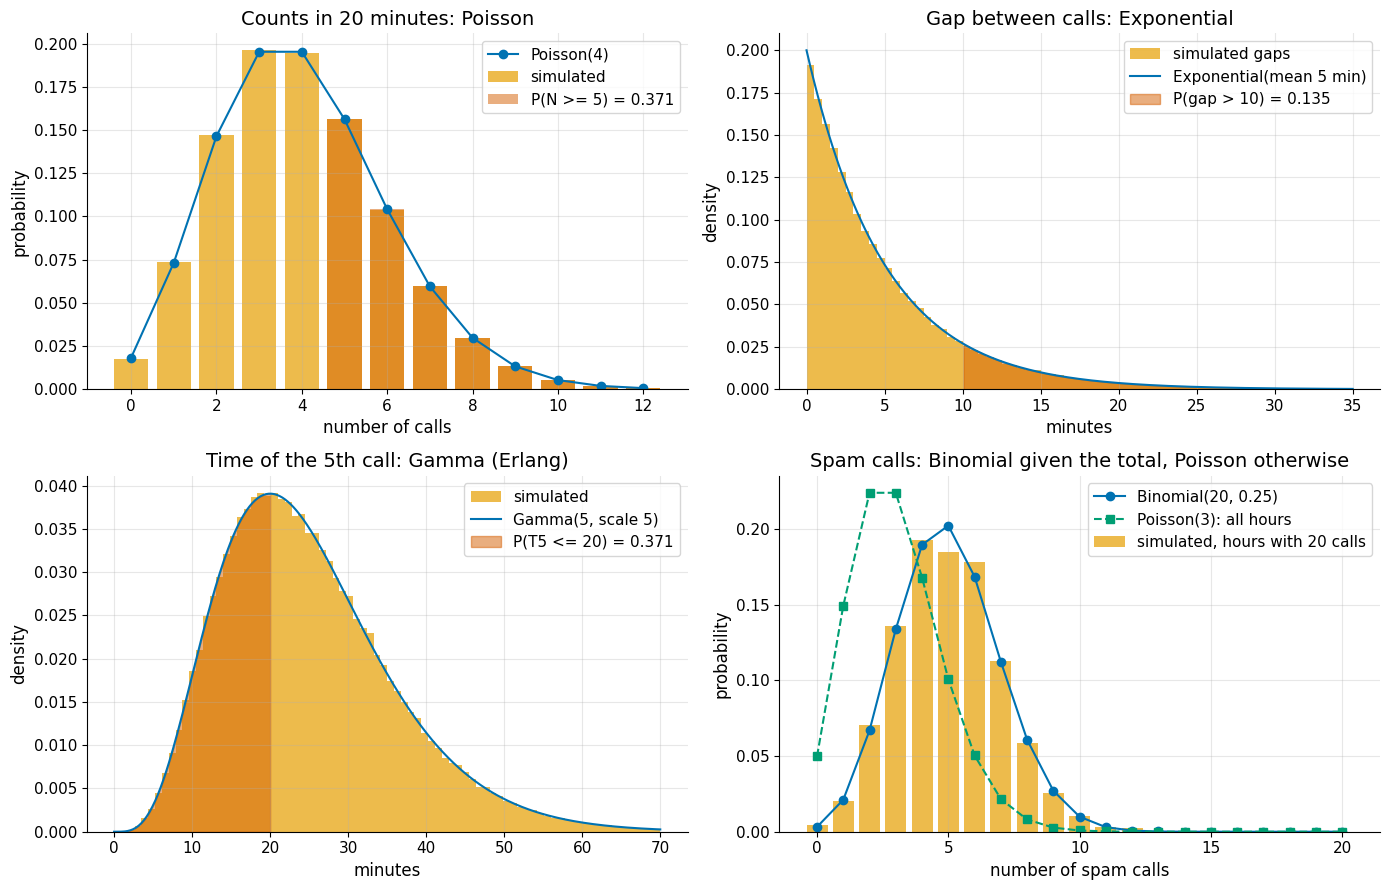

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ks = np.arange(0, 13)
axes[0, 0].bar(ks, np.bincount(calls_in_20, minlength=13)[:13] / n_hours, color=SIM, alpha=0.7, label="simulated")
axes[0, 0].plot(ks, stats.poisson(4).pmf(ks), "o-", color=MAIN, label="Poisson(4)")
axes[0, 0].bar(ks[ks >= 5], stats.poisson(4).pmf(ks[ks >= 5]), color=HIGHLIGHT, alpha=0.5, label=f"P(N >= 5) = {q1a_code:.3f}")
axes[0, 0].set_title("Counts in 20 minutes: Poisson")
axes[0, 0].set_xlabel("number of calls")
axes[0, 0].set_ylabel("probability")
axes[0, 0].legend()

t_axis = np.linspace(0, 70, 400)
axes[0, 1].hist(first_gap, bins=70, range=(0, 35), density=True, color=SIM, alpha=0.7, label="simulated gaps")
gap_axis = np.linspace(0, 35, 300)
axes[0, 1].plot(gap_axis, stats.expon(scale=5).pdf(gap_axis), color=MAIN, label="Exponential(mean 5 min)")
axes[0, 1].fill_between(gap_axis[gap_axis > 10], stats.expon(scale=5).pdf(gap_axis[gap_axis > 10]), color=HIGHLIGHT, alpha=0.5, label=f"P(gap > 10) = {q2a_code:.3f}")
axes[0, 1].set_title("Gap between calls: Exponential")
axes[0, 1].set_xlabel("minutes")
axes[0, 1].set_ylabel("density")
axes[0, 1].legend()

axes[1, 0].hist(fifth_call_time, bins=80, range=(0, 70), density=True, color=SIM, alpha=0.7, label="simulated")
axes[1, 0].plot(t_axis, stats.gamma(5, scale=5).pdf(t_axis), color=MAIN, label="Gamma(5, scale 5)")
axes[1, 0].fill_between(t_axis[t_axis <= 20], stats.gamma(5, scale=5).pdf(t_axis[t_axis <= 20]), color=HIGHLIGHT, alpha=0.5, label=f"P(T5 <= 20) = {q1b_code:.3f}")
axes[1, 0].set_title("Time of the 5th call: Gamma (Erlang)")
axes[1, 0].set_xlabel("minutes")
axes[1, 0].set_ylabel("density")
axes[1, 0].legend()

ks_spam = np.arange(0, 21)
axes[1, 1].bar(ks_spam, np.bincount(spam_in_hour[exactly_20], minlength=21)[:21] / exactly_20.sum(), color=SIM, alpha=0.7, label="simulated, hours with 20 calls")
axes[1, 1].plot(ks_spam, stats.binom(20, 0.25).pmf(ks_spam), "o-", color=MAIN, label="Binomial(20, 0.25)")
axes[1, 1].plot(ks_spam, stats.poisson(3).pmf(ks_spam), "s--", color=COLORS[2], label="Poisson(3): all hours")
axes[1, 1].set_title("Spam calls: Binomial given the total, Poisson otherwise")
axes[1, 1].set_xlabel("number of spam calls")
axes[1, 1].set_ylabel("probability")
axes[1, 1].legend()
plt.tight_layout()
plt.show()

### 11.5 Interpretation and decision
- **At least 5 calls in 20 minutes has probability 0.37**, whether you compute it from the count (Poisson) or from the arrival time of the 5th call (Gamma): they are two views of the same event. A manager can use whichever is more convenient.
- A quiet **10-minute gap occurs 13.5 % of the time** (Exponential), which is exactly the chance that a 10-minute window is empty (Poisson). A 10-minute silence is not a sign that anything is wrong.
- **Conditioning changes the question:** on an arbitrary hour at least 8 spam calls has probability only 1.2 % (Poisson(3)), but on an hour that already has 20 calls it is 10.2 % (Binomial(20, 0.25)): a busy hour simply has more spam. Knowing the total turns the Poisson into a Binomial and shifts the answer.
- **Decision:** staff for the Poisson counts, set alerts on Exponential gaps, and use the Binomial to plan spam filtering on busy hours. Because everything is one process, the three plans are consistent.

---
### Example 2: a quality-control lot through the approximations chain

**Scenario (illustrative).** A lot of **2,000 items** contains **40 defectives (2 %)**. An inspector samples **60 items** without replacement. What is $P(X\le1)$ (at most one defective found)?

Four candidate models, from exact to crude: **Hypergeometric** (exact), **Binomial(60, 0.02)** (ignores the lack of replacement), **Poisson(1.2)** (rare events), **Normal(1.2, 1.08) with continuity correction**. Which one can you trust?

**By hand.** Exact: $P(X\le1)=\dfrac{\binom{1960}{60}+40\binom{1960}{59}}{\binom{2000}{60}}$. Binomial: $0.98^{60}+60\cdot0.02\cdot0.98^{59}$. Poisson: $e^{-1.2}(1+1.2)=2.2\,e^{-1.2}=0.6626$. Normal: $\Phi\big(\frac{1.5-1.2}{1.0844}\big)=\Phi(0.277)=0.609$.

In [16]:
N_lot, K_defective, n_sample = 2000, 40, 60
p_defective = K_defective / N_lot

exact_hand = (math.comb(N_lot - K_defective, n_sample) + K_defective * math.comb(N_lot - K_defective, n_sample - 1)) / math.comb(N_lot, n_sample)
binomial_hand = (1 - p_defective) ** n_sample + n_sample * p_defective * (1 - p_defective) ** (n_sample - 1)
poisson_hand = math.exp(-n_sample * p_defective) * (1 + n_sample * p_defective)
normal_hand = 0.5 * (1 + math.erf(((1.5 - n_sample * p_defective) / math.sqrt(n_sample * p_defective * (1 - p_defective))) / math.sqrt(2)))

exact_code = stats.hypergeom(M=N_lot, n=K_defective, N=n_sample).cdf(1)
binomial_code = stats.binom(n_sample, p_defective).cdf(1)
poisson_code = stats.poisson(n_sample * p_defective).cdf(1)
normal_code = stats.norm(n_sample * p_defective, np.sqrt(n_sample * p_defective * (1 - p_defective))).cdf(1.5)
for hand, code in [(exact_hand, exact_code), (binomial_hand, binomial_code), (poisson_hand, poisson_code), (normal_hand, normal_code)]:
    assert np.isclose(hand, code)

comparison = pd.DataFrame({"model": ["Hypergeometric (exact)", "Binomial(60, 0.02)", "Poisson(1.2)", "Normal(1.2, 1.08), continuity corrected"],
                           "P(X <= 1)": [exact_code, binomial_code, poisson_code, normal_code]})
comparison["error vs exact"] = comparison["P(X <= 1)"] - exact_code
print(comparison.round(5).to_string(index=False))
simulated = rng.hypergeometric(K_defective, N_lot - K_defective, n_sample, size=1_000_000)
print(f"simulation of the inspection: {np.mean(simulated <= 1):.5f} (exact {exact_code:.5f})")
assert abs(np.mean(simulated <= 1) - exact_code) < 0.002

                                  model  P(X <= 1)  error vs exact
                 Hypergeometric (exact)    0.66092         0.00000
                     Binomial(60, 0.02)    0.66190         0.00099
                           Poisson(1.2)    0.66263         0.00171
Normal(1.2, 1.08), continuity corrected    0.60897        -0.05195
simulation of the inspection: 0.66064 (exact 0.66092)


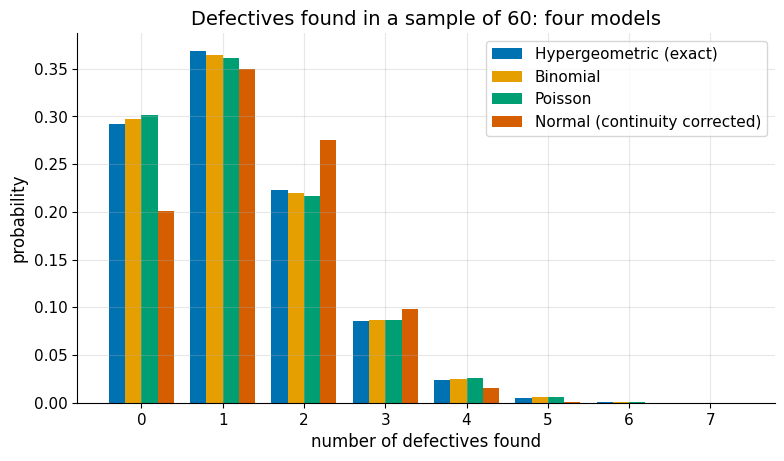

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ks = np.arange(0, 8)
ax.bar(ks - 0.3, stats.hypergeom(N_lot, K_defective, n_sample).pmf(ks), width=0.2, color=MAIN, label="Hypergeometric (exact)")
ax.bar(ks - 0.1, stats.binom(n_sample, p_defective).pmf(ks), width=0.2, color=COLORS[1], label="Binomial")
ax.bar(ks + 0.1, stats.poisson(1.2).pmf(ks), width=0.2, color=COLORS[2], label="Poisson")
ax.bar(ks + 0.3, stats.norm(1.2, 1.0844).cdf(ks + 0.5) - stats.norm(1.2, 1.0844).cdf(ks - 0.5), width=0.2, color=HIGHLIGHT, label="Normal (continuity corrected)")
ax.set_title("Defectives found in a sample of 60: four models")
ax.set_xlabel("number of defectives found")
ax.set_ylabel("probability")
ax.legend()
plt.show()

**Interpretation.** The lesson is the **chain of approximations**: Hypergeometric $\to$ Binomial (sample is only 3 % of the lot: error 0.001) $\to$ Poisson (rare defects: error 0.002) $\to$ Normal (mean only 1.2: error 0.05). **Each step is fine when its assumption holds and crude when it does not**: the Normal approximation of a count with mean 1.2 is unreliable because the distribution is far from symmetric. For rare events use Poisson or Binomial, never Normal. (04_02 quantifies when each approximation is safe.)

---
### Example 3: a statistics chain: Normal, chi-square, t and F on one data set

**Scenario (illustrative).** A machine should fill bottles with a mean of **5.0 units**. Eight bottles give a sample mean of **5.2** and a sample SD of **0.6**. Is the machine off target?

The statistic is $T=\dfrac{\bar x-5}{s/\sqrt8}$. Its null distribution can be reached by **two routes**: directly as a Student $t_7$, or as $T^2\sim F_{1,7}$. A third view: $T$ is a Normal divided by $\sqrt{\chi^2_7/7}$.

**By hand.** $\mathrm{SE}=0.6/\sqrt8=0.2121$, $T=\frac{0.2}{0.2121}=0.943$; the two-sided 5 % critical value from the table is $t_{0.975,7}=2.365$, so we do not reject. The F route: $T^2=0.889$ against $F_{0.95}(1,7)=5.59=2.365^2$.

In [18]:
n_bottles, sample_mean, sample_sd, target = 8, 5.2, 0.6, 5.0
standard_error = sample_sd / math.sqrt(n_bottles)
t_hand = (sample_mean - target) / standard_error
t_critical_table = 2.365
print(f"SE = {standard_error:.4f}, T = {t_hand:.4f}, T^2 = {t_hand ** 2:.4f}; critical t = {t_critical_table}, critical t^2 = {t_critical_table ** 2:.3f}")

p_via_t = 2 * stats.t(n_bottles - 1).sf(abs(t_hand))
p_via_f = stats.f(1, n_bottles - 1).sf(t_hand**2)
assert np.isclose(p_via_t, p_via_f)
assert np.isclose(stats.f(1, 7).ppf(0.95), stats.t(7).ppf(0.975) ** 2)
assert np.isclose(t_critical_table, stats.t(7).ppf(0.975), atol=0.001)
print(f"two-sided p-value via t(7) = {p_via_t:.4f}; via F(1, 7) = {p_via_f:.4f}  (the same number)")

# the third view: T = Z / sqrt(chi2_7 / 7), simulated from its ingredients under the null
z = rng.normal(size=500_000)
chi_square_7 = (rng.normal(size=(500_000, 7)) ** 2).sum(axis=1)
simulated_t = z / np.sqrt(chi_square_7 / 7)
p_via_simulation = np.mean(np.abs(simulated_t) >= abs(t_hand))
print(f"p-value from simulating Z / sqrt(chi2/7): {p_via_simulation:.4f}")
assert abs(p_via_simulation - p_via_t) < 0.004

SE = 0.2121, T = 0.9428, T^2 = 0.8889; critical t = 2.365, critical t^2 = 5.593
two-sided p-value via t(7) = 0.3772; via F(1, 7) = 0.3772  (the same number)
p-value from simulating Z / sqrt(chi2/7): 0.3768


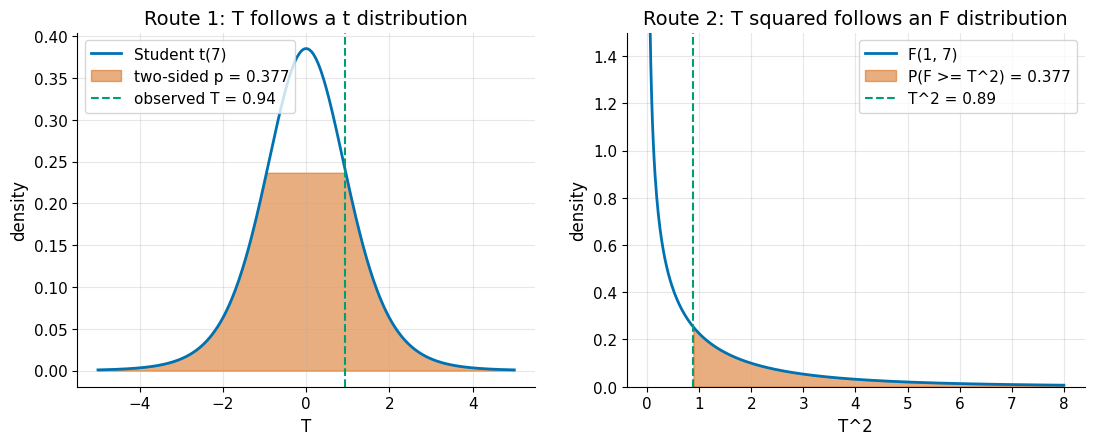

In [19]:
fig, (ax_t, ax_f) = plt.subplots(1, 2, figsize=(13, 4.6))
t_axis = np.linspace(-5, 5, 500)
ax_t.plot(t_axis, stats.t(7).pdf(t_axis), color=MAIN, linewidth=2, label="Student t(7)")
tail = np.abs(t_axis) >= abs(t_hand)
ax_t.fill_between(t_axis[tail], stats.t(7).pdf(t_axis[tail]), color=HIGHLIGHT, alpha=0.5, label=f"two-sided p = {p_via_t:.3f}")
ax_t.axvline(t_hand, color=COLORS[2], linestyle="--", label=f"observed T = {t_hand:.2f}")
ax_t.set_title("Route 1: T follows a t distribution")
ax_t.set_xlabel("T")
ax_t.set_ylabel("density")
ax_t.legend()
f_axis = np.linspace(0.01, 8, 500)
ax_f.plot(f_axis, stats.f(1, 7).pdf(f_axis), color=MAIN, linewidth=2, label="F(1, 7)")
ax_f.fill_between(f_axis[f_axis >= t_hand**2], stats.f(1, 7).pdf(f_axis[f_axis >= t_hand**2]), color=HIGHLIGHT, alpha=0.5, label=f"P(F >= T^2) = {p_via_f:.3f}")
ax_f.axvline(t_hand**2, color=COLORS[2], linestyle="--", label=f"T^2 = {t_hand ** 2:.2f}")
ax_f.set_ylim(0, 1.5)
ax_f.set_title("Route 2: T squared follows an F distribution")
ax_f.set_xlabel("T^2")
ax_f.set_ylabel("density")
ax_f.legend()
plt.show()

**Interpretation.** Both routes give the same **p-value 0.38**: the sample mean of 5.2 is **not significantly different** from 5.0 with only 8 bottles (the machine may be fine, or the test lacks power). The point is structural: **t, chi-square and F are one family**: $T=Z/\sqrt{\chi^2/\nu}$, $T^2\sim F_{1,\nu}$, so a t test and a one-degree-of-freedom F test are the same test. Knowing the tree lets you move to whichever form your software offers.

## 12. Where it is used

### Statistics
- **Deriving distributions and tests:** t, chi-square and F from Normals; conjugate priors from mixtures; exact tests from conditioning (Fisher's exact test: Poisson/Binomial to Hypergeometric).
- **Choosing approximations** (Poisson for rare events, Normal for large counts) and knowing their error (04_02).

### Data science
- **Simulating from any distribution** with the recipes (inverse CDF, sums, ratios), synthetic data generation.
- **Modelling overdispersed counts** with the Gamma-Poisson (Negative Binomial) mixture; modelling event streams with Poisson, Exponential and Gamma consistently.

### ML and AI
- **Reparameterization and sampling tricks** (Gumbel-max, Normal from Uniforms), Dirichlet from Gammas for topic models, Student-t as a Normal scale mixture for robust models, Beta-Binomial for click-through rates with a Beta prior.

## 13. Common pitfalls and misconceptions

- **A relationship needs its conditions:** sums stay in a family only for *independent* variables, and often only with the *same* scale or success probability (Gamma with the same scale; Binomial with the same p).
- **Limits are approximations, not identities:** a Normal never equals a Binomial; always check the error (04_02).
- **Parameter conventions hide special cases:** `scipy` uses scale, not rate; `geom` starts at 1 and `nbinom` at 0; Lognormal uses `scale = exp(mu)`.
- **Conditioning changes the family:** Poisson given a total is Binomial, not Poisson; mixing a Poisson over a random rate is Negative Binomial, not Poisson.
- **A transformation of a Normal is rarely Normal:** only linear maps preserve it.
- **Two routes must agree:** if two derivations give different answers, one has a mistake (a good self-check).

## 14. Exercises

1. The number of customers in an hour is Poisson(18). Each is a returning customer with probability $1/3$ (independently). What is the distribution of returning customers per hour? What is the probability of at least 8? Check with a simulation of the thinning.
2. Show with MGFs that the sum of two independent Gamma($k_1,\theta$) and Gamma($k_2,\theta$) is Gamma($k_1+k_2,\theta$). Why does it fail if the scales differ?
3. A call centre sees 6 calls in a given 30-minute window. Given this, what is the distribution of the number of calls in the first 10 minutes? (Use the conditioning relationship: Poisson given the total.)
4. $X\sim\text{Exp}(1)$. Find, by the CDF method, the distribution of $Y=X^{1/2}$ and name it (Weibull with which parameters?).
5. Run the verification of section 9 for three relationships of your own choice that are not in the table (for example Gamma(0.5, 2) vs chi-square(1), and the sum of 3 Uniform(0,1) against its Irwin-Hall density).
6. (Harder) Show that a Negative Binomial with mean $\mu$ and size $r$ tends to a Poisson($\mu$) as $r\to\infty$ (the mixing Gamma becomes a point mass). Verify numerically for $\mu=4$, $r=1,10,100,1000$ with the total variation distance.

Solutions are at the end.

## 15. Summary table

| Mechanism | Tool | Typical examples |
|---|---|---|
| Sum | MGF / PGF product | Bernoulli to Binomial; Exponential to Gamma; squares to chi-square; Normal + Normal |
| Transformation | CDF method, inverse CDF | exp(Normal), -ln U, ratios giving t, F, Cauchy, Beta; differences giving Laplace, Logistic |
| Limit | MGF limits, CLT | Binomial to Poisson to Normal; Gamma, t, chi-square to Normal; maxima to Gumbel |
| Special case | read off the density | Exponential = Gamma(1); chi-square = Gamma(nu/2, 2); Cauchy = t(1); Beta(1,1) = Uniform |
| Mixture | integrate over the parameter | Gamma-Poisson = Negative Binomial; Beta-Binomial; Normal scale mixture = t |
| Conditioning | Bayes / ratio of probabilities | Poisson given the sum = Binomial; order statistics = Beta; memoryless Exponential |

## Solutions

In [20]:
returning = stats.poisson(18 / 3)
thinned = rng.binomial(rng.poisson(18, 500_000), 1 / 3)
print("1: Poisson(6); P(>= 8) =", round(returning.sf(7), 4), " simulated thinning:", round(np.mean(thinned >= 8), 4), " mean/variance of the thinned counts:", round(thinned.mean(), 3), round(thinned.var(), 3))
print("3: given 6 calls in 30 min, calls in the first 10 min ~ Binomial(6, 1/3); mean =", 6 / 3, " P(0) =", round(stats.binom(6, 1 / 3).pmf(0), 4))
y = np.sqrt(rng.exponential(1, 300_000))
print("4: sqrt of an Exp(1): KS vs Weibull(k = 2, scale 1) p-value =", round(stats.kstest(y, stats.weibull_min(2, scale=1).cdf).pvalue, 3))
print("5: Gamma(0.5, scale 2) = chi-square(1):", np.allclose(stats.gamma(0.5, scale=2).pdf(x), stats.chi2(1).pdf(x)))
irwin_hall = U((200_000, 3)).sum(axis=1)
print("5: sum of 3 Uniform(0,1) vs Irwin-Hall (scipy.stats.irwinhall) KS p-value:", round(stats.kstest(irwin_hall, stats.irwinhall(3).cdf).pvalue, 3))
mu = 4
for r in (1, 10, 100, 1000):
    support = np.arange(0, 40)
    tv = 0.5 * np.abs(stats.nbinom(r, r / (r + mu)).pmf(support) - stats.poisson(mu).pmf(support)).sum()
    print(f"6: NegBin(mean 4, size {r:4d}) vs Poisson(4): total variation = {tv:.4f}")

1: Poisson(6); P(>= 8) = 0.256  simulated thinning: 0.2563  mean/variance of the thinned counts: 6.002 6.008
3: given 6 calls in 30 min, calls in the first 10 min ~ Binomial(6, 1/3); mean = 2.0  P(0) = 0.0878
4: sqrt of an Exp(1): KS vs Weibull(k = 2, scale 1) p-value = 0.709
5: Gamma(0.5, scale 2) = chi-square(1): True


5: sum of 3 Uniform(0,1) vs Irwin-Hall (scipy.stats.irwinhall) KS p-value: 0.294
6: NegBin(mean 4, size    1) vs Poisson(4): total variation = 0.3850
6: NegBin(mean 4, size   10) vs Poisson(4): total variation = 0.0832
6: NegBin(mean 4, size  100) vs Poisson(4): total variation = 0.0098
6: NegBin(mean 4, size 1000) vs Poisson(4): total variation = 0.0010


**1.** Thinning: returning customers $\sim$ Poisson($18/3=6$); $P(\ge8)=0.2560$ (mean and variance of the simulated thinned counts both near 6).

**2.** $M(t)=(1-\theta t)^{-k}$ for Gamma($k,\theta$); the product of two such MGFs with the same $\theta$ is $(1-\theta t)^{-(k_1+k_2)}$. With different scales the product $(1-\theta_1t)^{-k_1}(1-\theta_2t)^{-k_2}$ is not of the form $(1-\theta t)^{-k}$, so the sum is not Gamma.

**3.** Given the total of 6 calls in 30 minutes, each call falls in the first 10 minutes independently with probability $10/30$: the count is Binomial($6,\tfrac13$) with mean 2.

**4.** $P(X^{1/2}\le y)=P(X\le y^2)=1-e^{-y^2}$: Weibull with shape 2 and scale 1 (a Rayleigh distribution).

**5.** Gamma($\tfrac12$, scale 2) is the chi-square with 1 d.f. (identical densities); the sum of 3 Uniform(0,1) values follows the Irwin-Hall density (the KS test agrees).

**6.** The total variation distance shrinks as $r$ grows (printed): the Negative Binomial converges to the Poisson because a Gamma mixing distribution with a very large shape is nearly a point mass at the mean.